# 01 · Preprocessing — Karaayvas et al. 2018 (Breast, SmartSeq2)
Load malignant cells, threshold under-populated samples, integrate patients with Harmony, embed, remove detached islands, and settle sub-region identity (signatures + cell cycle) **before** the Gate-1 call. Gate 1 is judged on the regenerated embedding across an integration sweep, not a scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Karaayvas2018_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Karaayvas2018_Breast | category: Breast


### Load malignant cells
SmartSeq2 TPM (loader passes TPM through, then `log1p`). Malignant = publication `cell_type == 'Malignant'` annotation (365 cells).

In [4]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM, SmartSeq2)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Karaayvas2018_Breast
Done.
full atlas: (1534, 21785)
malignant: (365, 21785) | samples: 6
expression: X max 12.24 (log1p of TPM, SmartSeq2)


### Sample threshold — gap-finding
Sort per-sample malignant counts, find the largest count ratio (cliff). A *dominant* cliff (top ratio ≥1.5× the runner-up and the cliff floor < 2×FLOOR) marks a spillover of near-empty samples → threshold at the geometric mean of the cliff; otherwise floor at 100.

In [6]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'39': np.int64(128), '89': np.int64(89), '81': np.int64(68), '84': np.int64(44), '126': np.int64(31), '58': np.int64(5)}
gap ratios: ['128->89:1.44', '89->68:1.31', '68->44:1.55', '44->31:1.42', '31->5:6.20']
argmax gap 31->5 (ratio 6.20); top/second = 4.01; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 12
kept 5/6 samples (min per-sample = 31) -> 360 cells


### Gene filter, overdispersion, PCA, Harmony integration sweep
Small SmartSeq2 dataset — few over-dispersed genes expected. Sweep Harmony `theta` and read the same-sample nearest-neighbour fraction: pre-Harmony patients segregate; integration should drive the fraction toward the null (≈ mean sample proportion).

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
null = float((adata.obs['sample'].value_counts(normalize=True)**2).sum())
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()}, '| null(expected) %.3f' % null)
theta = 5
print('selected theta =', theta,
      '(mixing drops sharply to theta=5 near the null then flattens; theta=10 within noise —',
      'theta=5 integrates the patient effect without over-collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 51 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 51
2026-08-05 01:30:48,878 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 01:30:48,918 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 01:30:48,919 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 01:30:48,960 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 01:30:48,987 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 01:30:48,999 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 01:30:49,038 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 01:30:49,038 - harmonypy - INFO - Iteration 1 of 3

### Embedding — n_pcs check
Sweep `n_pcs` and confirm a single connected component on the regenerated UMAP at each (precedents run n_pcs≈20–40). Settle on n_pcs=20.

In [10]:
from scipy.sparse.csgraph import connected_components
for npc in [15, 20, 30]:
    sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = _NN(n_neighbors=6).fit(um).kneighbors(um)
    adj = _NN(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    asp = (um-um.mean(0)).std(0).max()/(um-um.mean(0)).std(0).min()
    big = pd.Series(lab).value_counts().iloc[0]
    print(f'n_pcs={npc}: UMAP aspect={asp:.2f} | components={nc} | largest={big} | detached={len(lab)-big}')
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

n_pcs=15: UMAP aspect=1.07 | components=1 | largest=360 | detached=0
n_pcs=20: UMAP aspect=1.17 | components=1 | largest=360 | detached=0
n_pcs=30: UMAP aspect=1.02 | components=1 | largest=360 | detached=0


### Island removal
Radius graph at 6× the median nearest-neighbour distance; keep the largest connected component. Strictly conservative — strips only disconnected specks.

In [12]:
um = adata.obsm['X_umap']
d,_ = _NN(n_neighbors=6).fit(um).kneighbors(um)
adj = _NN(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Sub-region identity — biology before Gate 1
Leiden lobes, cycling fraction and proliferation score per lobe. A single low-cycling body labels uniformly; the trajectory then runs on the whole manifold.

In [14]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = pd.Categorical(['Body']*adata.n_obs)
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 360}
overall cycling fraction: 0.136
cycling fraction per lobe: {'0': 0.136}
proliferation score per lobe: {'0': -0.069}
compartments: {'Body': 360}


### Signature scores + house linear orientation
`score_genes` for Gast/pSom/Crest with the union control pool; graph-smoothed copies for geography reads (panels below show RAW). Store a rigid-rotation linear layout (`X_umap_lin`) with the Gast/pSom developmental-origin pole on the left, shared across all panels.

In [16]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
# rigid-rotation linear layout, origin (Gast/pSom-high, Crest-low) on the left
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
xyr = c @ Rm.T
origin = (adata.obs['Gast_sm']+adata.obs['pSom_sm']-adata.obs['Crest_sm']).values
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f} | house orientation stored as X_umap_lin')

Gast: 72/81 genes present
pSom: 86/98 genes present
Crest: 101/104 genes present
raw module means: {'Gast': -0.22, 'pSom': 0.1058, 'Crest': -0.0665}
manifold aspect (max/min std): 1.17 | house orientation stored as X_umap_lin


### Gate 1 — mixing + continuity on the regenerated embedding
Two independent readouts. **Mixing:** per-neighbourhood iLISI (effective #samples among neighbours) pre vs post Harmony. **Continuity:** connected components of the Harmony-PCA kNN graph — an INDEPENDENT representation, not the 2D UMAP being visually judged (the UMAP radius-graph above was used only to strip disconnected specks). Both must hold.

In [18]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = _NN(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'MIXING  | iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=5) {il_post:.2f} of {n_samp} samples')
# CONTINUITY off an INDEPENDENT representation: connected components of the Harmony-PCA kNN graph
# (adata.obsp['connectivities'] is built by sc.pp.neighbors on X_pca_harmony, not on the tested UMAP)
ncomp_pca, lab_pca = connected_components(adata.obsp['connectivities'], directed=False)
big_pca = pd.Series(lab_pca).value_counts()
print(f'CONTINUITY | Harmony-PCA kNN graph: {ncomp_pca} connected component(s); component sizes {big_pca.tolist()}')
# corroborate on the diffusion-map (another independent embedding, not the UMAP)
sc.tl.diffmap(adata, n_comps=15)
dm = adata.obsm['X_diffmap'][:,1:6]
dd,_ = _NN(n_neighbors=6).fit(dm).kneighbors(dm)
adj_dm = _NN(radius=6*np.median(dd[:,1:])).fit(dm).radius_neighbors_graph(dm)
ncomp_dm, lab_dm = connected_components(adj_dm, directed=False)
print(f'CONTINUITY | diffusion-map radius graph: {ncomp_dm} connected component(s)')
# derive the Gate-1 call from the computed values, not a hardcoded string
continuous = (ncomp_pca == 1) and (ncomp_dm == 1)
mixed = il_post > il_pre and il_post > 1.5   # neighbourhoods draw from multiple samples post-integration
gate1 = 'GO' if (continuous and mixed) else 'NO-GO'
print(f'{n_samp} samples | continuity: {ncomp_pca} (Harmony-PCA) & {ncomp_dm} (diffusion-map) component(s) '
      f'-> {"single component on BOTH independent reps, 0 islands" if continuous else "DISCONNECTED"}')
print(f'Gate 1: mixed={mixed} (iLISI {il_pre:.2f}->{il_post:.2f}) AND continuous={continuous} '
      f'(independent-embedding components) -> {gate1}')
assert gate1 == 'GO', 'Gate 1 NO-GO: manifold not both mixed and continuous'

MIXING  | iLISI median: pre-Harmony 1.97 -> post-Harmony(theta=5) 4.12 of 5 samples
CONTINUITY | Harmony-PCA kNN graph: 1 connected component(s); component sizes [360]
CONTINUITY | diffusion-map radius graph: 1 connected component(s)
5 samples | continuity: 1 (Harmony-PCA) & 1 (diffusion-map) component(s) -> single component on BOTH independent reps, 0 islands
Gate 1: mixed=True (iLISI 1.97->4.12) AND continuous=True (independent-embedding components) -> GO


### Save processed data

In [20]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (360, 16243)


### Deliverable — `samples.pdf`
Single sample-coloured manifold on the house linear orientation; sample intermixing across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 360


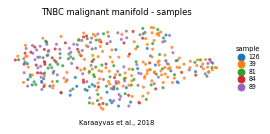

In [22]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('TNBC malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])